# Assignment 6
Develop a model that predicts movie ratings for users based on previous rating patterns and
recommend movies accordingly. Use MovieLens Dataset from Link:https://grouplens.org/datasets/movielens/

### Import Libraries

In [22]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.layers import Concatenate, Dropout
from tensorflow.keras.models import Model

### Import datasets

In [5]:
ratings = pd.read_csv("ratings.csv")
ratings

,userId,movieId,rating,timestamp
0,1,2,3.5,1112486027
1,1,29,3.5,1112484676
2,1,32,3.5,1112484819
3,1,47,3.5,1112484727
4,1,50,3.5,1112484580
...,...,...,...,...
1048570,7120,168,5.0,1175543061
1048571,7120,253,4.0,1175542225
1048572,7120,260,5.0,1175542035
1048573,7120,261,4.0,1175543376


In [6]:
movies = pd.read_csv("movies.csv")
movies

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
27273,131254,Kein Bund für's Leben (2007),Comedy
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)


Merge - Encode

In [8]:
df = ratings.merge(movies, on='movieId')
df

,userId,movieId,rating,timestamp,title,genres
0,1,2,3.5,1112486027,Jumanji (1995),Adventure|Children|Fantasy
1,1,29,3.5,1112484676,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi
2,1,32,3.5,1112484819,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller
3,1,47,3.5,1112484727,Seven (a.k.a. Se7en) (1995),Mystery|Thriller
4,1,50,3.5,1112484580,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
...,...,...,...,...,...,...
1048570,7120,168,5.0,1175543061,First Knight (1995),Action|Drama|Romance
1048571,7120,253,4.0,1175542225,Interview with the Vampire: The Vampire Chroni...,Drama|Horror
1048572,7120,260,5.0,1175542035,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
1048573,7120,261,4.0,1175543376,Little Women (1994),Drama


### Label encoding

In [16]:
user_encoder = LabelEncoder()
movie_encoder = LabelEncoder()

ratings["user"] = user_encoder.fit_transform(ratings["userId"])
ratings["movie"] = movie_encoder.fit_transform(ratings["movieId"])

In [17]:
num_users = ratings["user"].nunique()
num_movies = ratings["movie"].nunique()

print("Users :", num_users)
print("Movies:", num_movies)

Users : 7120
Movies: 14026


### Training and testing

In [18]:
X = ratings[["user","movie"]]
y = ratings["rating"].astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### Embedded model

In [23]:
embedding_size = 50

user_input = Input(shape=(1,))
movie_input = Input(shape=(1,))

user_embedding = Embedding(
    input_dim=num_users,
    output_dim=embedding_size
)(user_input)

movie_embedding = Embedding(
    input_dim=num_movies,
    output_dim=embedding_size
)(movie_input)

user_vec = Flatten()(user_embedding)
movie_vec = Flatten()(movie_embedding)

x = Concatenate()([user_vec, movie_vec])

x = Dense(256, activation="relu")(x)
x = Dropout(0.3)(x)

x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)

x = Dense(64, activation="relu")(x)

x = Dense(32, activation="relu")(x)

output = Dense(1)(x)


In [24]:
model = Model(
    inputs=[user_input, movie_input],
    outputs=output
)

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │    356,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 1, 50)     │    701,300 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 50)        │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 50)        │          0 │ embedding_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 100)       │          0 │ flatten[0][0],    │
│ (Concatenate)       │                   │            │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │     25,856 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128)       │     32,896 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 1)         │         33 │ dense_3[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,126,421 (4.30 MB)

 Trainable params: 1,126,421 (4.30 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
history = model.fit(
    [X_train.user, X_train.movie],
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    verbose=1
)

Epoch 1/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 54s 20ms/step - loss: 0.9223 - mae: 0.7330 - val_loss: 0.7545 - val_mae: 0.6769
Epoch 2/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 80s 19ms/step - loss: 0.7320 - mae: 0.6586 - val_loss: 0.7396 - val_mae: 0.6681
Epoch 3/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 49s 19ms/step - loss: 0.6948 - mae: 0.6402 - val_loss: 0.7134 - val_mae: 0.6471
Epoch 4/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 82s 19ms/step - loss: 0.6619 - mae: 0.6246 - val_loss: 0.7079 - val_mae: 0.6450
Epoch 5/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 48s 18ms/step - loss: 0.6281 - mae: 0.6073 - val_loss: 0.7115 - val_mae: 0.6416
Epoch 6/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 84s 19ms/step - loss: 0.5938 - mae: 0.5901 - val_loss: 0.7126 - val_mae: 0.6449
Epoch 7/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 49s 19ms/step - loss: 0.5619 - mae: 0.5734 - val_loss: 0.7188 - val_mae: 0.6514
Epoch 8/20
2622/2622 ━━━━━━━━━━━━━━━━━━━━ 48s 18ms/step - loss: 0.5337 - mae: 0.5584 - val_loss: 0.7206 - val_mae: 0.6499
Epoch 9/20
2622/2622 ━━━

### Metrics evaluation

In [26]:
loss, mae = model.evaluate(
    [X_test.user, X_test.movie],
    y_test,
    verbose=0
)

In [27]:
rmse = np.sqrt(loss)

print("\nRMSE :", rmse)
print("MAE :", mae)


RMSE : 0.8718889652350633
MAE : 0.6661165356636047


### Train vs Validate Loss over Epochs

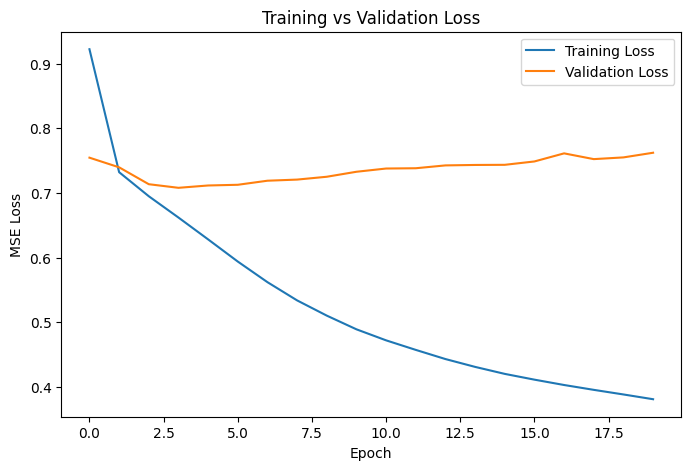

In [38]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")

plt.legend()

plt.show()

### Predictions

In [39]:
user = 0
movie = 50

pred = model.predict(
    [
        np.array([user]),
        np.array([movie])
    ],
    verbose=0
)

print("Predicted Rating =", pred[0][0])

Predicted Rating = 3.2157311


In [33]:
predictions = model.predict(
    [
        X_test["user"].values,
        X_test["movie"].values
    ],
    verbose=0
)
results = pd.DataFrame({
    "User": user_encoder.inverse_transform(X_test.user.values),
    "Movie": movie_encoder.inverse_transform(X_test.movie.values),
    "Actual Rating": y_test.values,
    "Predicted Rating": predictions.flatten()
})

# Display first 10 samples
print("\nSample Prediction Results")
print(results.head(10))


Sample Prediction Results
   User  Movie  Actual Rating  Predicted Rating
0  5207    529            4.0          4.119010
1  6298   4226            5.0          4.178155
2  6081     16            1.0          1.659030
3  5224   1206            4.0          4.630946
4  4401   6541            1.0          1.925667
5  1929   2688            3.5          3.230119
6  2397    172            3.0          3.484877
7  4998    474            5.0          4.614065
8  2543   4896            3.0          2.925574
9   134   2640            3.0          3.157188


### Function for Movie Recommendations

In [34]:
def recommend_movies(user_id, top_n=10):

    watched = ratings.loc[ratings["userId"] == user_id, "movieId"]

    rated_movies = ratings["movieId"].unique()

    unseen = movies[
        (movies["movieId"].isin(rated_movies)) &
        (~movies["movieId"].isin(watched))
    ].copy()

    user_encoded = user_encoder.transform([user_id])[0]
    movie_encoded = movie_encoder.transform(unseen["movieId"])

    predictions = model.predict(
        [
            np.full(len(movie_encoded), user_encoded),
            movie_encoded
        ],
        verbose=0
    ).flatten()

    unseen["Predicted Rating"] = predictions

    recommendations = unseen.sort_values(
        "Predicted Rating",
        ascending=False
    ).head(top_n)

    print(recommendations[["title", "genres", "Predicted Rating"]])
    print("\nTop Recommended Movies")
    print("-"*90)

    for _, row in recommendations.iterrows():
        print(f"{row['title']:<60} {row['Predicted Rating']:.2f}")

In [35]:
recommend_movies(user_id=1, top_n=10)

                             title                      genres  \
10593                    Babylon 5                      Sci-Fi   
9431      Iron Jawed Angels (2004)               Drama|Romance   
15927   Alice in Wonderland (1933)  Adventure|Children|Fantasy   
12415         Clean, Shaven (1993)                 Crime|Drama   
19271              Bob Funk (2009)              Comedy|Romance   
11615          Five Fingers (2006)              Drama|Thriller   
15976            Dirty Girl (2010)                Comedy|Drama   
8516   King Solomon's Mines (1950)    Action|Adventure|Romance   
17538                Sombre (1998)                Drama|Horror   
1435               Best Men (1997)   Action|Comedy|Crime|Drama   

       Predicted Rating  
10593          4.695652  
9431           4.690105  
15927          4.663737  
12415          4.656656  
19271          4.636734  
11615          4.608480  
15976          4.570204  
8516           4.544775  
17538          4.533646  
1435         

In [37]:
recommend_movies(user_id=77, top_n=7)

                                                   title        genres  \
10593                                          Babylon 5        Sci-Fi   
10584                              Calamari Union (1985)        Comedy   
10161           Innocent Voices (Voces inocentes) (2004)     Drama|War   
12415                               Clean, Shaven (1993)   Crime|Drama   
23765                             Wish I Was Here (2014)  Comedy|Drama   
9952   Special Day, A (Giornata particolare, Una) (1977)     Drama|War   
17983                               Examined Life (2008)   Documentary   

       Predicted Rating  
10593          5.046395  
10584          4.843083  
10161          4.785124  
12415          4.775425  
23765          4.774332  
9952           4.741506  
17983          4.739286  

Top Recommended Movies
------------------------------------------------------------------------------------------
Babylon 5                                                    5.05
Calamari Union (19